In [2]:
!git clone https://github.com/its-sampada/nepali-news-classifier.git


Cloning into 'nepali-news-classifier'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 0), reused 4 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.


In [3]:
%cd nepali-news-classifier

/content/nepali-news-classifier


In [4]:
!pip install pandas numpy scikit-learn datasets matplotlib seaborn joblib

In [5]:
from datasets import load_dataset

dataset = load_dataset("Titung/16nepali-news")

train_data = dataset['train']
test_data = dataset['test']

print(dataset)
print(train_data[0])

README.md:   0%|          | 0.00/428 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 22.7MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.82MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.85MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11478 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1435 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1435 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_id'],
        num_rows: 11478
    })
    validation: Dataset({
        features: ['text', 'label', 'label_id'],
        num_rows: 1435
    })
    test: Dataset({
        features: ['text', 'label', 'label_id'],
        num_rows: 1435
    })
})
{'text': 'बंग्लादेशमा भइरहेको यु-१९ विश्वकपमा नेपालले न्यूजील्याण्ड विरुद्ध २३८ रन बनाएको छ। नेपालले निर्धारित ५० ओभरमा ७ विकेट गुमाएर यो योगफल तयार पार्दै न्युजील्याण्डलाई २३९ रनको चुनौति दिएको हो। यो नेपालले यु-१९ विश्वकप अन्तर्गतका भएका खेलको एकै इनिङमा बनाएको सर्वाधिक रन हो। यसअघि सन् २००६मा आयरल्याण्ड विरुद्धको २३४ रन नै नेपालको सर्वाधिक रन थियो। यु-१९ विश्वकपमा नेपालले २०० रन कटाएको पनि यो साताौं पटक नै हो।', 'label': 12, 'label_id': 'Sports'}


In [6]:
import pandas as pd

train_df = dataset['train'].to_pandas()
val_df = dataset['validation'].to_pandas()
test_df = dataset['test'].to_pandas()

print("Training shape: ", train_df.shape)
print("Validation shape: ", val_df.shape)
print("Testing shape: ", test_df.shape)

train_df.head()

Training shape:  (11478, 3)
Validation shape:  (1435, 3)
Testing shape:  (1435, 3)


,text,label,label_id
0,बंग्लादेशमा भइरहेको यु-१९ विश्वकपमा नेपालले न्...,12,Sports
1,"राजविराज, १३ असार । सोमवार विहान वर्षासँगै परे...",10,National News
2,काठमाडौं । नेकपा एमालेका अध्यक्ष केपी शर्मा ओल...,10,National News
3,"राजविराज, २३ भदौ । मधेशी युवा विद्यार्थी मोर्च...",10,National News
4,अर्थमन्त्री डा. रामशरण महतले नेपाल कुनै हालतमा...,10,National News


In [7]:
print('Available categories: \n')

categories= train_df['label_id'].unique()

for category in categories:
    print(category)

print('\n Total categories: ', len(categories))


Available categories: 

Sports
National News
Economy
Entertainment
Opinion
Education
Tourism
Bank
Interview
Employment
World
Literature
Blog
Technology
Business Interview
Auto

 Total categories:  16


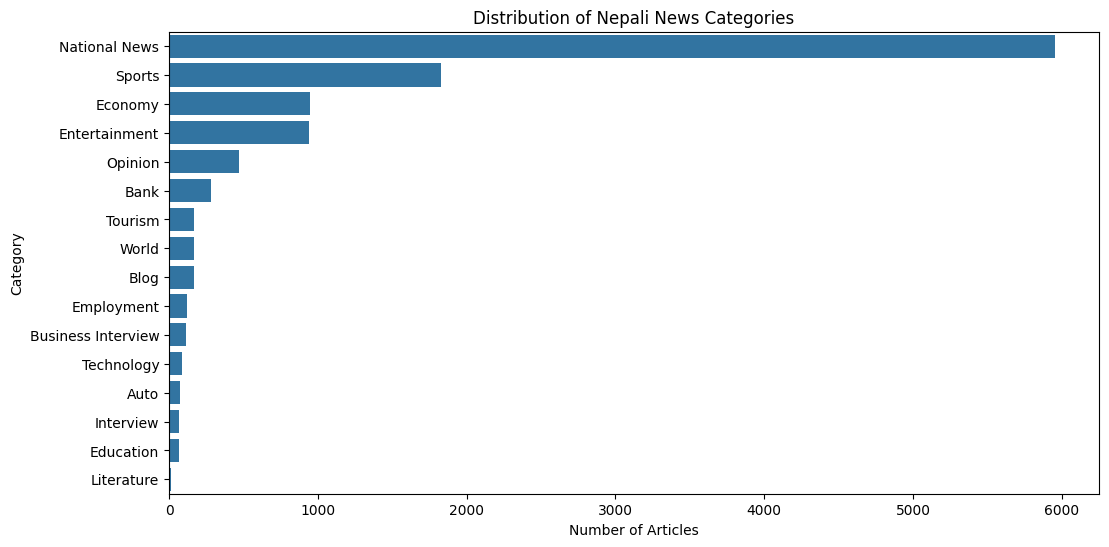

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    data=train_df,
    y="label_id",
    order=train_df["label_id"].value_counts().index
)

plt.title("Distribution of Nepali News Categories")
plt.xlabel("Number of Articles")
plt.ylabel("Category")

plt.show()

In [9]:
print("Missing values:")
print(train_df.isnull().sum())

Missing values:
text        0
label       0
label_id    0
dtype: int64


In [10]:
print("Duplicate articles:", train_df["text"].duplicated().sum())


Duplicate articles: 0


count    11478.000000
mean      2008.070396
std       2112.430805
min         55.000000
25%        806.000000
50%       1280.000000
75%       2272.000000
max      21668.000000
Name: text_length, dtype: float64


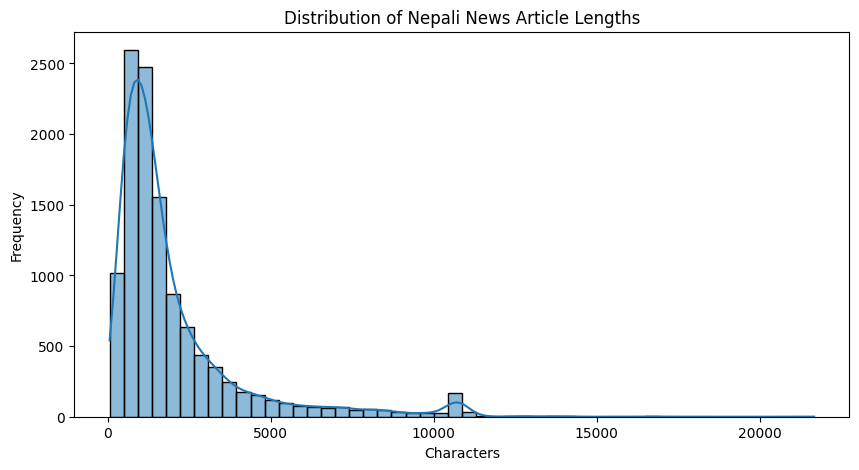

In [11]:
train_df["text_length"] = train_df["text"].apply(len)

print(train_df["text_length"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["text_length"],
    bins=50,
    kde=True
)

plt.title("Distribution of Nepali News Article Lengths")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

In [12]:
category_counts = train_df["label_id"].value_counts()

category_distribution = pd.DataFrame({
    "Count": category_counts,
    "Percentage": (
        category_counts / len(train_df) * 100
    ).round(2)
})

print(category_distribution)

                    Count  Percentage
label_id                             
National News        5953       51.86
Sports               1828       15.93
Economy               949        8.27
Entertainment         938        8.17
Opinion               470        4.09
Bank                  281        2.45
Tourism               171        1.49
World                 170        1.48
Blog                  167        1.45
Employment            122        1.06
Business Interview    114        0.99
Technology             88        0.77
Auto                   76        0.66
Interview              70        0.61
Education              68        0.59
Literature             13        0.11


In [13]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} distribution:")
    print(
        df["label_id"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


Train distribution:
label_id
National News         51.86
Sports                15.93
Economy                8.27
Entertainment          8.17
Opinion                4.09
Bank                   2.45
Tourism                1.49
World                  1.48
Blog                   1.45
Employment             1.06
Business Interview     0.99
Technology             0.77
Auto                   0.66
Interview              0.61
Education              0.59
Literature             0.11
Name: proportion, dtype: float64

Validation distribution:
label_id
National News         51.85
Sports                15.96
Economy                8.29
Entertainment          8.15
Opinion                4.11
Bank                   2.44
Blog                   1.46
Tourism                1.46
World                  1.46
Employment             1.11
Business Interview     0.98
Technology             0.77
Auto                   0.70
Education              0.63
Interview              0.56
Literature             0.07
Name: 

In [14]:
# Input features
X_train = train_df["text"]
X_val = val_df["text"]
X_test = test_df["text"]

# Target labels
y_train = train_df["label_id"]
y_val = val_df["label_id"]
y_test = test_df["label_id"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 11478
Validation samples: 1435
Testing samples: 1435


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    max_features=50000,
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)

X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (11478, 50000)
Validation matrix: (1435, 50000)
Testing matrix: (1435, 50000)


In [16]:
print("Total vocabulary size:", len(tfidf.vocabulary_))

print("\nFirst 30 vocabulary words:")

for word in list(tfidf.vocabulary_.keys())[:30]:
    print(word)

Total vocabulary size: 50000

First 30 vocabulary words:
शम
भइरह
१९
वकपम
लल
रन
बन
एक
५०
ओभरम
एर
गफल
तय
डल
रनक
वकप
अन
तर
गतक
भएक
लक
इन
ङम
सर
यसअघ
सन
आयरल
धक
२००
कट


In [17]:
# Select one article
sample_text = X_train.iloc[0]

# Transform it
sample_vector = tfidf.transform([sample_text])

print("Original article:")
print(sample_text)

print("\nTF-IDF vector shape:")
print(sample_vector.shape)

print("\nNon-zero features:")
print(sample_vector.nnz)

Original article:
बंग्लादेशमा भइरहेको यु-१९ विश्वकपमा नेपालले न्यूजील्याण्ड विरुद्ध २३८ रन बनाएको छ। नेपालले निर्धारित ५० ओभरमा ७ विकेट गुमाएर यो योगफल तयार पार्दै न्युजील्याण्डलाई २३९ रनको चुनौति दिएको हो। यो नेपालले यु-१९ विश्वकप अन्तर्गतका भएका खेलको एकै इनिङमा बनाएको सर्वाधिक रन हो। यसअघि सन् २००६मा आयरल्याण्ड विरुद्धको २३४ रन नै नेपालको सर्वाधिक रन थियो। यु-१९ विश्वकपमा नेपालले २०० रन कटाएको पनि यो साताौं पटक नै हो।

TF-IDF vector shape:
(1, 50000)

Non-zero features:
57


In [18]:
from sklearn.naive_bayes import MultinomialNB

model_nb = MultinomialNB()

model_nb.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [19]:
model_nb.fit(X_train_tfidf, y_train)

MultinomialNB()

In [20]:
y_pred = model_nb.predict(X_val_tfidf)

In [21]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_val, y_pred))

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        y_pred,
        zero_division=0
    )
)

Accuracy: 0.5881533101045296

Classification Report:

                    precision    recall  f1-score   support

              Auto       0.00      0.00      0.00        10
              Bank       0.00      0.00      0.00        35
              Blog       0.00      0.00      0.00        21
Business Interview       0.00      0.00      0.00        14
           Economy       0.00      0.00      0.00       119
         Education       0.00      0.00      0.00         9
        Employment       0.00      0.00      0.00        16
     Entertainment       1.00      0.10      0.19       117
         Interview       0.00      0.00      0.00         8
        Literature       0.00      0.00      0.00         1
     National News       0.56      0.99      0.71       744
           Opinion       0.00      0.00      0.00        59
            Sports       0.91      0.43      0.58       229
        Technology       0.00      0.00      0.00        11
           Tourism       0.00      0.00      

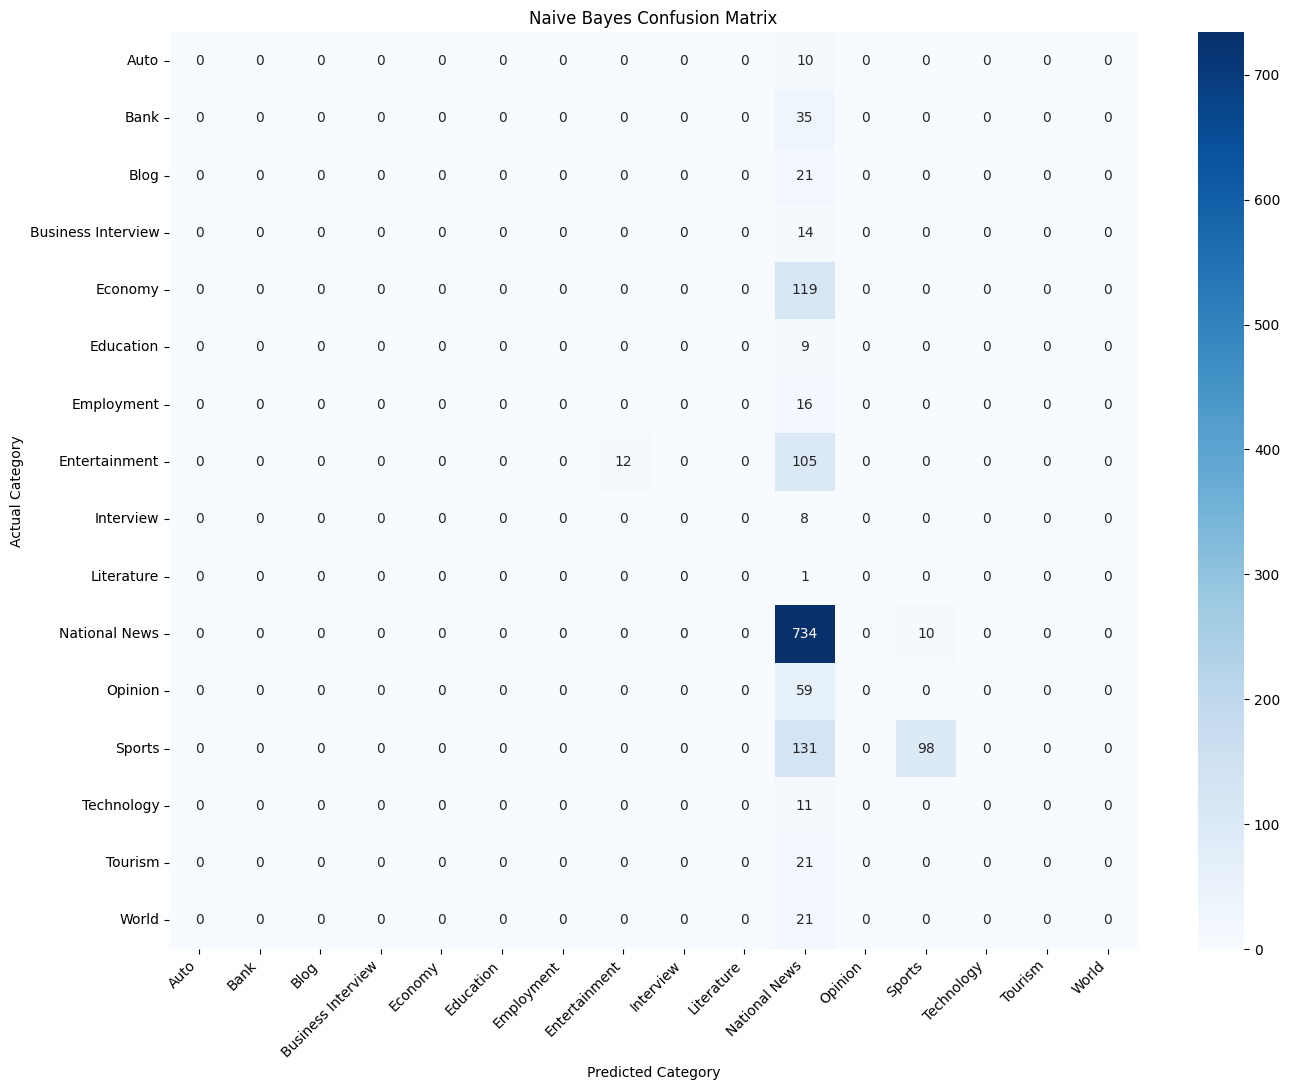

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=model_nb.classes_
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model_nb.classes_,
    yticklabels=model_nb.classes_
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_v2 = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    max_features=50000,
    min_df=2,
    sublinear_tf=True
)

X_train_v2 = tfidf_v2.fit_transform(X_train)
X_val_v2 = tfidf_v2.transform(X_val)

print("Training matrix:", X_train_v2.shape)
print("Validation matrix:", X_val_v2.shape)

print("\nFirst 30 vocabulary terms:")
print(
    list(tfidf_v2.get_feature_names_out())[:30]
)

Training matrix: (11478, 50000)
Validation matrix: (1435, 50000)

First 30 vocabulary terms:
['!', '! अब', '! तर,', '! म', '! यो', '!"', "!'", '"', '"अनि', '"अब', '"अहिले', '"एक', '"काम', '"कुनै', '"के', '"केही', '"तर', '"तर,', '"त्यसपछि', '"त्यसैले', '"त्यही', '"त्यो', '"दुई', '"नयाँ', '"नेपाल', '"नेपालको', '"नेपाली', '"पहिले', '"म', '"मलाई']


In [24]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_lr.fit(X_train_v2, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [25]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_pred_lr = model_lr.predict(X_val_v2)

print("Accuracy:", accuracy_score(y_val, y_pred_lr))

print(
    "Macro F1:",
    f1_score(y_val, y_pred_lr, average="macro")
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        y_pred_lr,
        zero_division=0
    )
)

Accuracy: 0.7665505226480837
Macro F1: 0.671945086926532

Classification Report:

                    precision    recall  f1-score   support

              Auto       0.53      0.80      0.64        10
              Bank       0.58      0.89      0.70        35
              Blog       0.50      0.81      0.62        21
Business Interview       0.81      0.93      0.87        14
           Economy       0.51      0.71      0.59       119
         Education       0.41      0.78      0.54         9
        Employment       0.39      0.75      0.51        16
     Entertainment       0.83      0.78      0.80       117
         Interview       0.30      0.38      0.33         8
        Literature       1.00      1.00      1.00         1
     National News       0.94      0.73      0.82       744
           Opinion       0.55      0.95      0.70        59
            Sports       0.84      0.86      0.85       229
        Technology       0.78      0.64      0.70        11
           Touris

In [26]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

results = pd.DataFrame([
    {
        "Model": "Naive Bayes (Original TF-IDF)",
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(
            y_val, y_pred, average="macro"
        )
    },
    {
        "Model": "Logistic Regression (Improved TF-IDF)",
        "Accuracy": accuracy_score(y_val, y_pred_lr),
        "Macro F1": f1_score(
            y_val, y_pred_lr, average="macro"
        )
    }
])

print(results)

                                   Model  Accuracy  Macro F1
0          Naive Bayes (Original TF-IDF)  0.588153  0.092539
1  Logistic Regression (Improved TF-IDF)  0.766551  0.671945


In [27]:
from sklearn.svm import LinearSVC

model_svm = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=3000
)

model_svm.fit(X_train_v2, y_train)

print("Linear SVM training completed!")

Linear SVM training completed!


In [28]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_pred_svm = model_svm.predict(X_val_v2)

print("Accuracy:", accuracy_score(y_val, y_pred_svm))

print(
    "Macro F1:",
    f1_score(y_val, y_pred_svm, average="macro")
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        y_pred_svm,
        zero_division=0
    )
)

Accuracy: 0.8236933797909408
Macro F1: 0.6193801010364905

Classification Report:

                    precision    recall  f1-score   support

              Auto       0.55      0.60      0.57        10
              Bank       0.65      0.86      0.74        35
              Blog       0.70      0.76      0.73        21
Business Interview       0.75      0.86      0.80        14
           Economy       0.62      0.63      0.62       119
         Education       0.50      0.56      0.53         9
        Employment       0.40      0.38      0.39        16
     Entertainment       0.84      0.78      0.81       117
         Interview       0.50      0.25      0.33         8
        Literature       0.00      0.00      0.00         1
     National News       0.90      0.87      0.88       744
           Opinion       0.69      0.95      0.80        59
            Sports       0.86      0.92      0.89       229
        Technology       0.86      0.55      0.67        11
           Touri

In [29]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    )
}

comparison = []

for name, model in models.items():

    model.fit(X_train_v2, y_train)

    predictions = model.predict(X_val_v2)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val,
            predictions,
            average="macro"
        ),
        "Weighted F1": f1_score(
            y_val,
            predictions,
            average="weighted"
        )
    })

results_v2 = pd.DataFrame(comparison)

print(
    results_v2.sort_values(
        by="Macro F1",
        ascending=False
    ).to_string(index=False)
)

              Model  Accuracy  Macro F1  Weighted F1
Logistic Regression  0.766551  0.671945     0.777896
         Linear SVM  0.823693  0.619380     0.822397
        Naive Bayes  0.649477  0.143781     0.571883


In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    max_features=50000,
    min_df=2,
    sublinear_tf=True
)

X_train_char = char_tfidf.fit_transform(X_train)
X_val_char = char_tfidf.transform(X_val)

print("Training shape:", X_train_char.shape)
print("Validation shape:", X_val_char.shape)

print("Vocabulary size:", len(char_tfidf.vocabulary_))

Training shape: (11478, 50000)
Validation shape: (1435, 50000)
Vocabulary size: 50000


In [31]:
model_char_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_char_lr.fit(X_train_char, y_train)

y_pred_char = model_char_lr.predict(X_val_char)

print("Accuracy:", accuracy_score(y_val, y_pred_char))

print(
    "Macro F1:",
    f1_score(y_val, y_pred_char, average="macro")
)

print(
    classification_report(
        y_val,
        y_pred_char,
        zero_division=0
    )
)

Accuracy: 0.7658536585365854
Macro F1: 0.6257433803826656
                    precision    recall  f1-score   support

              Auto       0.47      0.80      0.59        10
              Bank       0.61      0.89      0.72        35
              Blog       0.50      0.90      0.64        21
Business Interview       0.72      0.93      0.81        14
           Economy       0.55      0.71      0.62       119
         Education       0.30      0.78      0.44         9
        Employment       0.36      0.81      0.50        16
     Entertainment       0.82      0.72      0.76       117
         Interview       0.19      0.38      0.25         8
        Literature       0.33      1.00      0.50         1
     National News       0.95      0.73      0.83       744
           Opinion       0.55      0.92      0.69        59
            Sports       0.88      0.87      0.87       229
        Technology       0.70      0.64      0.67        11
           Tourism       0.56      0.86  

In [32]:
from scipy.sparse import hstack

X_train_combined = hstack([
    X_train_v2,
    X_train_char
]).tocsr()

X_val_combined = hstack([
    X_val_v2,
    X_val_char
]).tocsr()

print("Combined training shape:", X_train_combined.shape)
print("Combined validation shape:", X_val_combined.shape)

Combined training shape: (11478, 100000)
Combined validation shape: (1435, 100000)


In [33]:
model_combined = LogisticRegression(
    max_iter=1500,
    class_weight="balanced",
    random_state=42
)

model_combined.fit(X_train_combined, y_train)

y_pred_combined = model_combined.predict(
    X_val_combined
)

print("Accuracy:", accuracy_score(y_val, y_pred_combined))

print(
    "Macro F1:",
    f1_score(
        y_val,
        y_pred_combined,
        average="macro"
    )
)

print(
    classification_report(
        y_val,
        y_pred_combined,
        zero_division=0
    )
)

Accuracy: 0.7888501742160279
Macro F1: 0.6626317573246359
                    precision    recall  f1-score   support

              Auto       0.57      0.80      0.67        10
              Bank       0.60      0.86      0.71        35
              Blog       0.63      0.90      0.75        21
Business Interview       0.72      0.93      0.81        14
           Economy       0.55      0.72      0.63       119
         Education       0.41      0.78      0.54         9
        Employment       0.39      0.75      0.51        16
     Entertainment       0.80      0.76      0.78       117
         Interview       0.30      0.38      0.33         8
        Literature       0.50      1.00      0.67         1
     National News       0.94      0.77      0.85       744
           Opinion       0.59      0.93      0.72        59
            Sports       0.87      0.90      0.88       229
        Technology       0.78      0.64      0.70        11
           Tourism       0.60      0.71  

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

experiments = [
    ("Word LR", X_train_v2, X_val_v2, "LR"),
    ("Word SVM", X_train_v2, X_val_v2, "SVM"),
    ("Combined LR", X_train_combined, X_val_combined, "LR")
]

c_values = [0.1, 0.5, 1.0, 2.0, 5.0]

tuning_results = []

for name, Xtr, Xv, algorithm in experiments:

    for c in c_values:

        if algorithm == "LR":
            model = LogisticRegression(
                C=c,
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )

        else:
            model = LinearSVC(
                C=c,
                class_weight="balanced",
                max_iter=5000,
                random_state=42
            )

        model.fit(Xtr, y_train)

        predictions = model.predict(Xv)

        accuracy = accuracy_score(y_val, predictions)

        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro"
        )

        tuning_results.append({
            "Features + Model": name,
            "C": c,
            "Accuracy": accuracy,
            "Macro F1": macro_f1
        })

tuning_df = pd.DataFrame(tuning_results)

print(
    tuning_df.sort_values(
        by="Macro F1",
        ascending=False
    ).to_string(index=False)
)

Features + Model   C  Accuracy  Macro F1
     Combined LR 5.0  0.816028  0.698872
         Word LR 2.0  0.785366  0.692922
         Word LR 5.0  0.795819  0.688714
        Word SVM 0.5  0.806969  0.676262
         Word LR 1.0  0.766551  0.671945
     Combined LR 1.0  0.788850  0.662632
     Combined LR 2.0  0.797213  0.662305
        Word SVM 0.1  0.788850  0.659179
     Combined LR 0.5  0.766551  0.643061
         Word LR 0.5  0.749826  0.629118
        Word SVM 1.0  0.823693  0.619380
        Word SVM 2.0  0.823693  0.609092
        Word SVM 5.0  0.820906  0.603422
     Combined LR 0.1  0.719164  0.566760
         Word LR 0.1  0.691986  0.550529


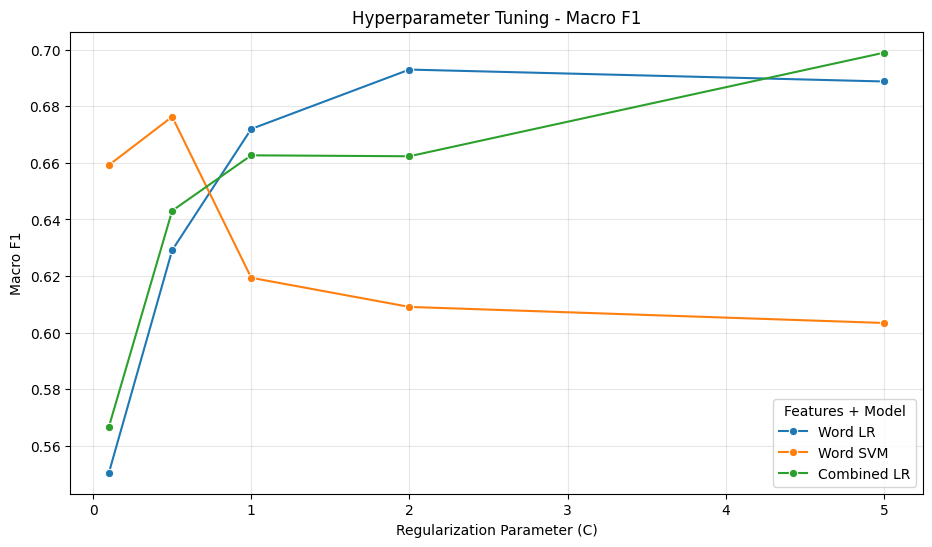

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=tuning_df,
    x="C",
    y="Macro F1",
    hue="Features + Model",
    marker="o"
)

plt.title("Hyperparameter Tuning - Macro F1")
plt.xlabel("Regularization Parameter (C)")
plt.ylabel("Macro F1")
plt.grid(alpha=0.3)

plt.show()


In [36]:
from sklearn.linear_model import LogisticRegression

best_model = LogisticRegression(
    C=5.0,
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

best_model.fit(X_train_combined, y_train)

best_predictions = best_model.predict(X_val_combined)

In [37]:
error_df = val_df.copy()

error_df["predicted"] = best_predictions

errors = error_df[
    error_df["label_id"] != error_df["predicted"]
].copy()

print("Total incorrect predictions:", len(errors))

print("Error rate:", round(
    len(errors) / len(val_df) * 100, 2
), "%")

display(
    errors[["text", "label_id", "predicted"]].head(10)
)

Total incorrect predictions: 264
Error rate: 18.4 %


,text,label_id,predicted
10,"२४ कात्तिक, काठमाडौं । प्रधानमन्त्री नरेन्द्र ...",Economy,Bank
18,"३ माघ, काठमाडौं । अष्ट्रेलियाले भारतलाई तेस्रो...",National News,Sports
23,पर्सा २५ पुस । विद्यार्थीहरुले आफनो क्षमतालाई ...,Economy,National News
31,विद्यालय व्यवस्थापन समिति गठनका विषयमा दलहरुबी...,Education,National News
33,निर्वासित तिब्बती नेता दलाइ लामाका मन्त्री अवै...,National News,Sports
37,संविधानको अन्तर्वस्तुप्रति असन्तुष्टि जनाउँदै ...,Interview,National News
50,"२२ बैशाख, काठमाडौं । नेपाल वायुसेवा निगमले ३२ ...",Economy,National News
51,"चिसापानी (काठमाडौं), २७ वैशाख काठमाडौं, सिन्धु...",National News,Economy
52,"३० फागुन, काठमाडौं । इभर्टनविरुद्धको खेलमा ग्य...",National News,Sports
54,छिमेकी प्रभूले दैलो उघार्लान् कि नाईं भन्दै ढु...,Blog,Opinion


In [38]:
confused = (
    errors.groupby(["label_id", "predicted"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(confused.head(15))

,label_id,predicted,count
32,National News,Economy,44
37,National News,Opinion,21
12,Economy,National News,17
38,National News,Sports,15
48,Sports,National News,12
22,Entertainment,Sports,11
35,National News,Entertainment,10
30,National News,Bank,9
34,National News,Employment,9
40,National News,World,8


In [39]:
from sklearn.metrics import classification_report

report = classification_report(
    y_val,
    best_predictions,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

display(
    report_df.sort_values("f1-score").round(3)
)

,precision,recall,f1-score,support
Interview,0.333,0.250,0.286,8.000
World,0.409,0.429,0.419,21.000
Employment,0.391,0.562,0.462,16.000
Auto,0.500,0.600,0.545,10.000
Education,0.538,0.778,0.636,9.000
Economy,0.599,0.689,0.641,119.000
macro avg,0.684,0.732,0.699,1435.000
Bank,0.638,0.857,0.732,35.000
Blog,0.680,0.810,0.739,21.000
Tourism,0.789,0.714,0.750,21.000


In [40]:
train_texts = set(train_df["text"])
val_texts = set(val_df["text"])
test_texts = set(test_df["text"])

print(
    "Train / Validation overlap:",
    len(train_texts & val_texts)
)

print(
    "Train / Test overlap:",
    len(train_texts & test_texts)
)

print(
    "Validation / Test overlap:",
    len(val_texts & test_texts)
)

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


In [41]:
confusion_examples = errors[
    (
        (errors["label_id"] == "National News") &
        (errors["predicted"] == "Economy")
    ) |
    (
        (errors["label_id"] == "Economy") &
        (errors["predicted"] == "National News")
    )
]

for _, row in confusion_examples.head(10).iterrows():

    print("\nActual:", row["label_id"])
    print("Predicted:", row["predicted"])
    print("Article:", row["text"][:500])
    print("-" * 80)


Actual: Economy
Predicted: National News
Article: पर्सा २५ पुस । विद्यार्थीहरुले आफनो क्षमतालाई प्रस्तुत गर्न सर्वप्रथम असल नागरीकको रुपमा आफुलाई प्रस्तुत गर्नुसक्नुपर्ने मेगा बैक वीरगंजका प्रमुख आमरत्व ओजश्वी उपाध्ययले बताएका छन् । वीरगंज पब्लीक कलेजले शनिवार होटल मकालुमा ११ कक्षामा अध्ययनरत विद्यार्थीहरुका लागि आयोजना गरेको 'सेल्फ एण्ड सेल' तालिम कार्यक्रमलाई सम्बोधन गर्दै प्रमुख अतिथि समेत रहेका उपाध्ययले अहिलेको प्रतिस्पर्धि युगमा विद्यार्थीहरुले असल नागरिक भए सफलता प्राप्त गर्न कठिनाई नरहेको बताउदै असल नागरिकका लागि आफुमा अबलम्बन गर्नुपर्न
--------------------------------------------------------------------------------

Actual: Economy
Predicted: National News
Article: २२ बैशाख, काठमाडौं । नेपाल वायुसेवा निगमले ३२ जना कर्मचारीको माग गर्दै अावेदन खुलाएको छ । १६ जना विमान परिचारिका(एयर होस्टेज) र १६ जना विमान परिचारक(क्याबिन क्रु) का लागि निगमनले बुधबार सार्वजानि सूचना नै प्रकाशित गरेर अावेदन खुल्ला गरेको हो । इच्छुक अावेदकले १ हजार रुपैंयाँ दस्तुर तिरेर निगमको केन्द्रिय कार्यालयमा

In [42]:
X_test_combined = hstack([
    tfidf_v2.transform(X_test),
    char_tfidf.transform(X_test)
]).tocsr()

print("Test matrix:", X_test_combined.shape)

Test matrix: (1435, 100000)


In [43]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_test_pred = best_model.predict(X_test_combined)

print(
    "Test Accuracy:",
    accuracy_score(y_test, y_test_pred)
)

print(
    "Test Macro F1:",
    f1_score(y_test, y_test_pred, average="macro")
)

print(
    "Test Weighted F1:",
    f1_score(y_test, y_test_pred, average="weighted")
)

print("\nFinal Classification Report:\n")

print(
    classification_report(
        y_test,
        y_test_pred,
        zero_division=0
    )
)

Test Accuracy: 0.8202090592334494
Test Macro F1: 0.7081471742083798
Test Weighted F1: 0.8233634261495054

Final Classification Report:

                    precision    recall  f1-score   support

              Auto       0.62      0.89      0.73         9
              Bank       0.70      0.86      0.77        35
              Blog       0.75      0.71      0.73        21
Business Interview       0.82      1.00      0.90        14
           Economy       0.61      0.70      0.65       119
         Education       0.44      0.50      0.47         8
        Employment       0.43      0.60      0.50        15
     Entertainment       0.85      0.76      0.80       118
         Interview       0.57      0.44      0.50         9
        Literature       1.00      1.00      1.00         2
     National News       0.93      0.82      0.87       744
           Opinion       0.67      0.95      0.78        59
            Sports       0.85      0.95      0.90       228
        Technology     

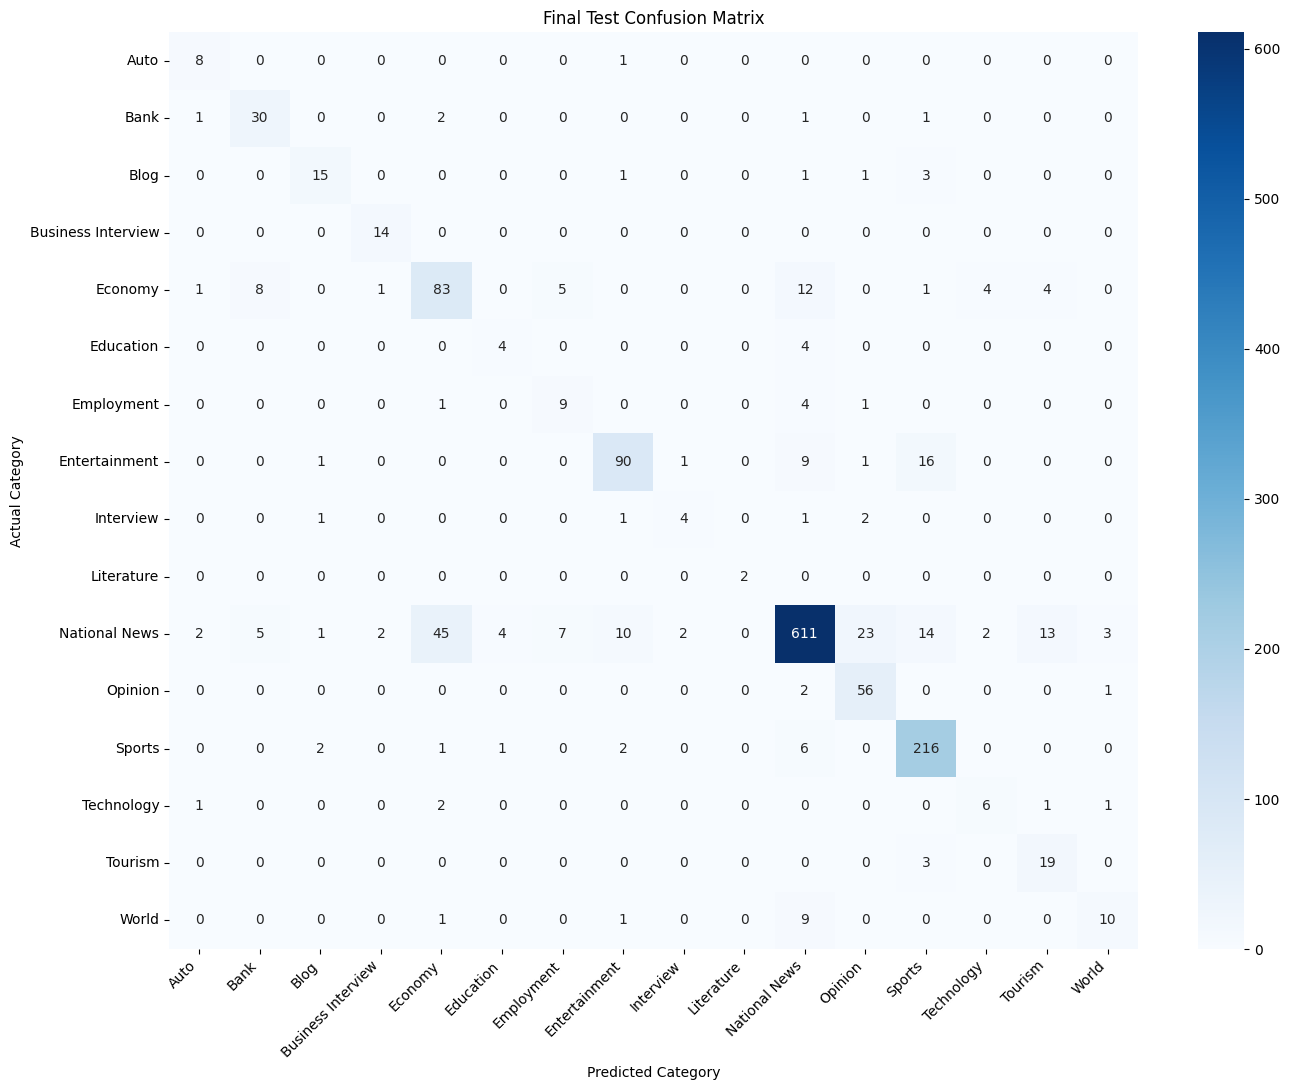

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=best_model.classes_
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [45]:
import os
import joblib

os.makedirs("models", exist_ok=True)

pipeline_data = {
    "word_vectorizer": tfidf_v2,
    "char_vectorizer": char_tfidf,
    "classifier": best_model,
    "classes": best_model.classes_
}

joblib.dump(
    pipeline_data,
    "models/nepali_news_pipeline.joblib",
    compress=3
)

print("Model saved successfully!")

Model saved successfully!


In [46]:
import os

model_path = "models/nepali_news_pipeline.joblib"

size_mb = os.path.getsize(model_path) / (1024 * 1024)

print("Model path:", model_path)
print("Model size:", round(size_mb, 2), "MB")

Model path: models/nepali_news_pipeline.joblib
Model size: 12.97 MB


In [47]:
loaded_pipeline = joblib.load(
    "models/nepali_news_pipeline.joblib"
)

loaded_word = loaded_pipeline["word_vectorizer"]
loaded_char = loaded_pipeline["char_vectorizer"]
loaded_model = loaded_pipeline["classifier"]

sample_news = X_test.iloc[0]

word_features = loaded_word.transform([sample_news])
char_features = loaded_char.transform([sample_news])

from scipy.sparse import hstack

combined_features = hstack([
    word_features,
    char_features
]).tocsr()

prediction = loaded_model.predict(combined_features)

print("News:")
print(sample_news)

print("\nPredicted category:", prediction[0])
print("Actual category:", y_test.iloc[0])

News:
प्रहरीको गोली लागेर १६ वर्षे नाति मारिएको पर्सिपल्ट उस्तै गरी ६८ वर्षे हजुरबुवाको निधन भयो। अघिल्लो मधेश आन्दोलनमा सम्भवतः सबैभन्दा पीडित बजराहीस्थित यो परिवारको विभत्स भोगाइ सुन्न मंगलबार बेलुकी हामी उनीहरूको घरमा उपस्थित थियौं। यो उनै रोहन चौधरीको घर हो, जो भदौ २३ गते गोली लागेर निधन नभइदिएको भए बिहीबारबाट सुरु हुने एसएलसी परीक्षाका लागि तयारी गरिरहेका देखिने थिए। हाम्रो समूह बाहिर बसेर कुरा गरिरहेकै बेला एक महिला घरको ढोकैमा उभिएर यो सबै दृश्य ब्याकुल भएर सु...

Predicted category: Blog
Actual category: Sports


In [48]:
from google.colab import files

files.download(
    "models/nepali_news_pipeline.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

sample_news = """झिलिमिली काठमाडौं
तिहारमा झिलिमिली बत्तीको प्रयोगसँगै यस वर्ष लक्ष्मीपूजाका दिन विद्युतको अधिकतम माग करिब १७ सय मेगावाट पुग्ने नेपाल विद्युत प्राधिकरणले अनुमान छ।"""

# Transform using both vectorizers
word_features = tfidf_v2.transform([sample_news])
char_features = char_tfidf.transform([sample_news])

sample_features = hstack([
    word_features,
    char_features
]).tocsr()

# Find similar training articles
similarities = cosine_similarity(
    sample_features,
    X_train_combined
).flatten()

top_indices = np.argsort(similarities)[::-1][:10]

for idx in top_indices:
    print("\nSimilarity:", round(similarities[idx], 3))
    print("Category:", y_train.iloc[idx])
    print("Article:", X_train.iloc[idx][:300])
    print("-" * 70)


Similarity: 0.306
Category: National News
Article: लक्ष्मी पूजाको रात काठमाडौं उपत्यकामा वत्तीको झिलिमिली १५ कात्तिक, काठमाडौं । वर्षभरीमा सबैभन्दा बढी विजुली खपत हुने दिन हो, तिहारको लक्ष्मी पूजा । यसपटकको लक्ष्मी पूजाका दिन १४ सय ४४ मेगावाट विजुली खपत भयो । नेपाल विद्युत प्राधिकरणका कार्यकारी निर्देशक कुलमान घिसिङका अनुसार यसपटकको लक्ष्मी पूजाका द
----------------------------------------------------------------------

Similarity: 0.268
Category: Sports
Article: वर्षकै सबैभन्दा बढी विद्युत् खपत हुने लक्ष्मीपूजाको दिन विद्युत् माग १ हजार ४ सय ४४ मेगावाट पुगेको छ । नेपाल विद्युत् प्राधिकरणका अनुसार सम्भवतः यो वर्षकै सबैभन्दा उच्च माग भएको समाचार आजको कारोबार दैनिकमा प्रकाशित भएको छ। प्राधिकरणले गत वर्षको तिहारमा वर्षकै सबैभन्दा बढी १३ सय ८५ मेगावाट पुगेको जना
----------------------------------------------------------------------

Similarity: 0.244
Category: National News
Article: १७ पुस, काठमाडौं । शनिबार मध्यरातिदेखि भारतबाट थप ४० मेगावाट विद्युत आयात भएको छ । यससँगै अब भारतबाट आयात ग

In [50]:
import numpy as np
import pandas as pd

val_probabilities = best_model.predict_proba(
    X_val_combined
)

max_scores = val_probabilities.max(axis=1)

val_predictions = best_model.classes_[
    val_probabilities.argmax(axis=1)
]

correct = (val_predictions == y_val.to_numpy())

threshold_results = []

for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:

    accepted = max_scores >= threshold

    threshold_results.append({
        "Threshold": threshold,
        "Coverage": round(accepted.mean() * 100, 2),
        "Accuracy when accepted": round(
            correct[accepted].mean() * 100, 2
        ) if accepted.any() else 0,
        "Accepted articles": int(accepted.sum())
    })

print(pd.DataFrame(threshold_results).to_string(index=False))

 Threshold  Coverage  Accuracy when accepted  Accepted articles
       0.2     99.93                   81.66               1434
       0.3     97.91                   82.42               1405
       0.4     92.33                   84.38               1325
       0.5     84.11                   87.90               1207
       0.6     73.94                   90.76               1061
       0.7     65.44                   92.65                939


In [51]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Select 200 random training articles
sample_indices = np.random.default_rng(42).choice(
    len(X_train),
    size=200,
    replace=False
)

suspicious_pairs = []

for idx in sample_indices:

    similarities = cosine_similarity(
        X_train_combined[idx],
        X_train_combined
    ).flatten()

    # Ignore the article itself
    similarities[idx] = 0

    # Find its nearest neighbour
    nearest_idx = np.argmax(similarities)

    similarity = similarities[nearest_idx]

    actual_category = y_train.iloc[idx]
    neighbour_category = y_train.iloc[nearest_idx]

    if (
        similarity >= 0.35
        and actual_category != neighbour_category
    ):
        suspicious_pairs.append({
            "Similarity": round(similarity, 3),
            "Article Category": actual_category,
            "Neighbour Category": neighbour_category,
            "Article": X_train.iloc[idx][:200],
            "Neighbour": X_train.iloc[nearest_idx][:200]
        })

print("Suspicious pairs:", len(suspicious_pairs))

for pair in sorted(
    suspicious_pairs,
    key=lambda x: x["Similarity"],
    reverse=True
)[:15]:

    print("\nSimilarity:", pair["Similarity"])
    print("Article category:", pair["Article Category"])
    print("Neighbour category:", pair["Neighbour Category"])
    print("Article:", pair["Article"])
    print("Neighbour:", pair["Neighbour"])
    print("-" * 80)

Suspicious pairs: 8

Similarity: 0.998
Article category: Interview
Neighbour category: Opinion
Article: मधेसी जनताको लडाइँको मुख्य मुद्दा अस्तित्व र पहिचानको हो । वास्तवमा मधेसी जनताले राज्यसत्तामा आफ्नो पहिचान र प्रतिनिधित्वको सुनिश्चितता चाहेका हुन् । त्यसैगरी मधेसमा रहेको वर्णाश्रम व्यवस्थाले पैदा गर
Neighbour: मधेसी जनताको लडाइँको मुख्य मुद्दा अस्तित्व र पहिचानको हो । वास्तवमा मधेसी जनताले राज्यसत्तामा आफ्नो पहिचान र प्रतिनिधित्वको सुनिश्चितता चाहेका हुन् । त्यसैगरी मधेसमा रहेको वर्णाश्रम व्यवस्थाले पैदा गर
--------------------------------------------------------------------------------

Similarity: 0.497
Article category: Sports
Neighbour category: National News
Article: ५ वैशाख, काठमाडौं । अन्तिम मिनेटमा पाएको पेनाल्टीमा ले गोल गरेपछि लिसेस्टर वेष्टहृयामसँग पराजित हुनबाट जोगिएको छ । र, प्रिमियर लिगको उपाधि नजिक पुगेको छ । आइतबार घरेलु मैदानमा भएको खेलमा लिग लिडर लिसे
Neighbour: १९ माघ, काठमाडौं । इंग्लिस प्रिमियर लिग फुटबलमा वेष्टब्रोमले लिग लिडर लिसेस्टरलाई बराबरीमा रोकेको छ । म

In [52]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

sample_indices = np.random.default_rng(42).choice(
    len(X_train),
    size=200,
    replace=False
)

suspicious_pairs = []

for idx in sample_indices:

    similarities = cosine_similarity(
        X_train_combined[idx],
        X_train_combined
    ).flatten()

    similarities[idx] = 0

    nearest_idx = np.argmax(similarities)
    similarity = similarities[nearest_idx]

    if (
        similarity >= 0.95
        and y_train.iloc[idx] != y_train.iloc[nearest_idx]
    ):

        suspicious_pairs.append({
            "similarity": similarity,
            "idx1": idx,
            "idx2": nearest_idx,
            "label1": y_train.iloc[idx],
            "label2": y_train.iloc[nearest_idx]
        })


for pair in suspicious_pairs:

    print("\n" + "=" * 80)

    print("Similarity:", round(pair["similarity"], 4))

    print("Article 1 category:", pair["label1"])
    print("Article 2 category:", pair["label2"])

    print("\nARTICLE 1:")
    print(X_train.iloc[pair["idx1"]])

    print("\nARTICLE 2:")
    print(X_train.iloc[pair["idx2"]])


Similarity: 0.9982
Article 1 category: Interview
Article 2 category: Opinion

ARTICLE 1:
मधेसी जनताको लडाइँको मुख्य मुद्दा अस्तित्व र पहिचानको हो । वास्तवमा मधेसी जनताले राज्यसत्तामा आफ्नो पहिचान र प्रतिनिधित्वको सुनिश्चितता चाहेका हुन् । त्यसैगरी मधेसमा रहेको वर्णाश्रम व्यवस्थाले पैदा गरेको जातीय अन्तरविरोध पनि त्यहाँको एउटा मुख्य समस्याको रूपमा रहेको छ । त्यसका अतिरिक्त मधेसी जनताले मधेसमा रहेको वर्गीय अन्तरविरोधको हल पनि खोजेका छन् । अर्थात् मधेसमा रहेका शोषक र शोषितबीचको अन्तरविरोध अर्को मुख्य समस्या हो । यिनले समाजका अन्य क्षेत्रलाई प्रभावित गरेको छ । काठमाडौंले मधेसलाई अहिलेसम्म उपयोग नै गरेको छ । मधेसको साधन–स्रोतलाई उपयोग गरेर काठमाडौंले आफैंमा केन्द्रीकरण गर्‍यो । तर, मधेसलाई त्यसबापत प्रतिफल दिन चाहेन । त्यसैले मधेसमा आज हिमाल र पहाडभन्दा बढी गरिबी छ, आवेश र आक्रोश ज्यादा छ । त्यसैगरी दिल्लीका शासकले मधेसलाई हतियार बनाउनेबाहेक कुनै काम गरेका छैनन् । लगानीकै कुरा गर्ने हो भने त्यहाँका शासकले मधेसभन्दा बढी पहाडमै लगानी गरेका छन् । दिल्लीले दिने छात्रवृत्ति मात्रै हेर्ने हो भने